## Exercise 3.1 [5.5p]

### Imports
Modules we will need in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy # for statistical tests

### **a)** P-values & Significance [3p]

The sample sets used in exercise 2.2 c & d, were only subsets (first 100 entries) of much bigger datasets. The complete datasets are provided in ```samples1_big.npz``` and ```samples2_big.npz```. These big sets contain 10.000 samples for each random variable including the 100 you saw in exercise 2.2. As a result, the statistical power of tests is higher. Perform the two t-tests from exercise 2.2 c & d again for the complete datasets (code provided below).

Processing samples1_big.npz
	distribution 1: N=10000, µ=4.985995, σ²=12.538433
	distribution 2: N=10000, µ=7.563971, σ²=12.364430


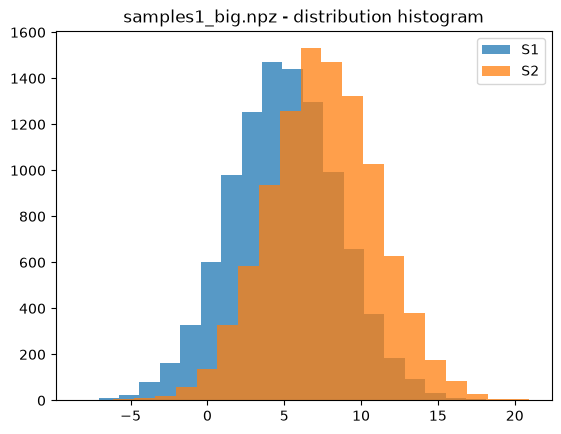

	p-value (t-test): 0.0000000000000000


Processing samples2_big.npz
	distribution 1: N=10000, µ=41.982422, σ²=6.219180
	distribution 2: N=10000, µ=41.996437, σ²=6.152843


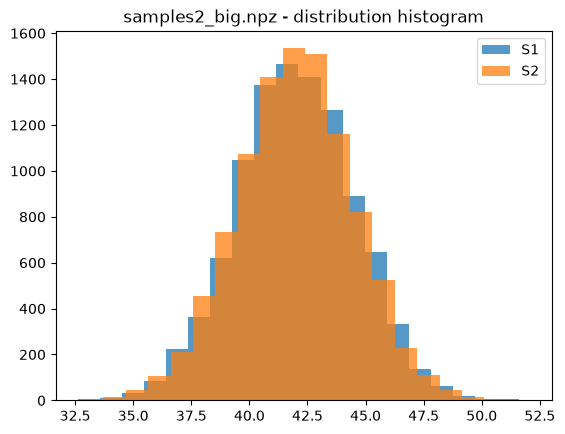

	p-value (t-test): 0.6903184634457173




In [2]:
# Code from exercise 2.2 c & d

#filePaths = ["samples1.npz", "samples2.npz"] # small sets from exercise 2.2
filePaths = ["samples1_big.npz", "samples2_big.npz"] #big sets from exercise 3.1

for datasetPath in filePaths: # do p-value testing for all provided datasets
    print(f"Processing {datasetPath}")

    # The following code is from exercise sheet 2 (and a bit optimized)
    npz_dict = np.load(datasetPath)
    D1_samples = npz_dict["D1_samples"]
    D2_samples = npz_dict["D2_samples"]

    #print characteristics
    print(f"\tdistribution 1: N={len(D1_samples)}, µ={np.mean(D1_samples):.6f}, σ²={np.var(D1_samples):.6f}" )
    print(f"\tdistribution 2: N={len(D2_samples)}, µ={np.mean(D2_samples):.6f}, σ²={np.var(D2_samples):.6f}" )

    # plot subset distribution
    bins = 20
    plt.figure()
    plt.title(f"{datasetPath} - distribution histogram")
    plt.hist(D1_samples, bins=bins, alpha=0.75, label="S1")
    plt.hist(D2_samples, bins=bins, alpha=0.75, label="S2")
    plt.legend() # plots labels
    plt.show()

    pvalue = scipy.stats.ttest_ind(D1_samples, D2_samples ).pvalue #reminder: H_0 means identical means of distributions
    print(f"\tp-value (t-test): {pvalue:.16f}\n\n") 


### Questions

**A)** How do each of the p-values change compared to exercise 2.2 c & d? **[1p]**

**SOLUTION**: They become more pronounced. Even though in the previous exercise, we could already see that the first 2 distributions weren't matching and we rejected H0, while the second 2 could have possible matched, here we see much bigger confidence. The first p goes all the way to 0 while the second one increases all the way to 0.7 instead of 0.2 previously.

**B)** How does this change our conclusions about the underlying distributions from witch we drew the samples? (answer for c & d each) **[1p]**



**SOLUTION**: It simply raises our confidence about the nature of these distributions and their similarities.

**C)** Why is this possible? Would it theoretically be possible that our conclusions would change yet again for even bigger datasets? How likely is that? **[1p]**

**SOLUTION**: I suppose theoretically yes, but this is already a big jump from 100 to 10000 samples where even visually, and in the moments, it becomes obvious whether the two distributions are similar or not.

### **b)** Maximum Likelihood Estimation [2.5p]

Given are 10 samples (```samples_pareto.npz```) drawn from a distribution. We know it was a [Type II Pareto](https://en.wikipedia.org/wiki/Lomax_distribution) distribution. What we do not know is parameter ```alpha```.

In the next cell we provide a function that computes the likelihood of alpha for a Type II Pareto distribution. It requires a set of samples (```xs```) from the target distribution.


In [3]:
def likelihood_pareto(alpha, xs, x_m=1):
    product = 1
    for x_i in xs:
        product*= (1+x_i/x_m)**-(alpha+1)
    r = ((alpha**len(xs))/(x_m**(len(xs))))*product
    return r

**A)** Use [np.linspace()](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html) to generate 21 equally spaced alpha values from 0 to 5. **[0.5p]**

In [4]:
alphas = np.linspace(start=0, stop=5, num=21)
print(alphas)

[0.   0.25 0.5  0.75 1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.   3.25
 3.5  3.75 4.   4.25 4.5  4.75 5.  ]


**B)** Compute the likelihood values for the above created alpha values (using ```likelihood_pareto()```) and plot them. **[1p]**

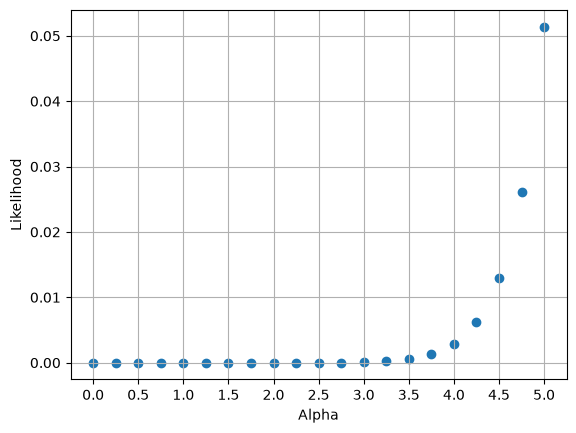

In [16]:
samples_pareto = np.load("samples_pareto.npz")["samples"] 

Likelihoods = []
for alpha in alphas:
    Likelihoods.append(likelihood_pareto(alpha, samples_pareto, -10))

#plot 
plt.figure()
plt.scatter(alphas,Likelihoods)
plt.xlabel("Alpha")
plt.ylabel("Likelihood")
plt.grid() #plots grid lines
plt.xticks(np.linspace(0, 5, 11)) # more fine grained x axis
plt.show()

**C)** Based on the above generated plot, argue what you think the missing parameter value of our pareto distribution is. **[1p]**

**SOLUTION**: It scales the distribution and also moves it along the x axis.
$\prod_{i=1}^n \frac{\alpha(1+x_i)^{-(\alpha+1)}}{x_m^{-\alpha}}$